<div style="
    background: linear-gradient(45deg,
        #d6eaf8,
        #f2f4f4 20%,
        #ffe5b4 40%,
        #ffffcc 60%,
        #d1f2eb 80%,
        #f3e5f5 100%
    );
    padding: 20px;
    margin: 20px 0;
    border-radius: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    font-family: Arial, sans-serif;
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
">
<h1><strong>Employee Productivity Analysis </strong></h1>
</div>

<div style="
    background: linear-gradient(45deg,
        #d6eaf8,
        #f2f4f4 20%,
        #ffe5b4 40%,
        #ffffcc 60%,
        #d1f2eb 80%,
        #f3e5f5 100%
    );
    padding: 20px;
    margin: 20px 0;
    border-radius: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    font-family: Arial, sans-serif;
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
">
<h2><strong>Author: - Girish Shenoy </strong></h2>
</div>

# The remaining part of the project is available in the following repository: [GitHub Repository](https://github.com/girishshen/Employee-Productivity-Analysis)

<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
    text-align: center;
">
    <h2><strong>Step 1 - Importing Libraries</strong></h2>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import kagglehub
import warnings

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer

import scipy.stats as stats
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import cross_val_score
import pickle

In [2]:
#pre-configure
pd.options.display.float_format = '{:.2f}'.format
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv("/kaggle/input/employee-performance-and-productivity-data/Extended_Employee_Performance_and_Productivity_Data.csv")

In [3]:
# Summary statistics
df.describe()

,Employee_ID,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,50000.50,41.03,4.48,3.00,6403.21,44.96,24.43,14.51,7.01,50.09,10.01,49.51,1.00,3.00
std,28867.66,11.24,2.87,1.41,1372.51,8.94,14.47,8.66,4.33,35.35,5.50,28.89,0.82,1.15
min,1.00,22.00,0.00,1.00,3850.00,30.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00
25%,25000.75,31.00,2.00,2.00,5250.00,37.00,12.00,7.00,3.00,25.00,5.00,25.00,0.00,2.01
50%,50000.50,41.00,4.00,3.00,6500.00,45.00,24.00,15.00,7.00,50.00,10.00,49.00,1.00,3.00
75%,75000.25,51.00,7.00,4.00,7500.00,53.00,37.00,22.00,11.00,75.00,15.00,75.00,2.00,3.99
max,100000.00,60.00,10.00,5.00,9000.00,60.00,49.00,29.00,14.00,100.00,19.00,99.00,2.00,5.00


In [4]:
# Get a summary of the dataset
print(f"Loaded {df.shape[0]} records and {df.shape[1]} columns.")

Loaded 100000 records and 20 columns.


In [5]:
# Check the data types of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  object 
 2   Gender                       100000 non-null  object 
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  object 
 5   Hire_Date                    100000 non-null  object 
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  object 
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  

In [6]:
# Check datatypes of each column
df.dtypes

Employee_ID                      int64
Department                      object
Gender                          object
Age                              int64
Job_Title                       object
Hire_Date                       object
Years_At_Company                 int64
Education_Level                 object
Performance_Score                int64
Monthly_Salary                 float64
Work_Hours_Per_Week              int64
Projects_Handled                 int64
Overtime_Hours                   int64
Sick_Days                        int64
Remote_Work_Frequency            int64
Team_Size                        int64
Training_Hours                   int64
Promotions                       int64
Employee_Satisfaction_Score    float64
Resigned                          bool
dtype: object

In [7]:
# Display First Few Rows of dataset
df.head()

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.00,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.00,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.00,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.00,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.00,38,11,29,13,100,15,9,1,1.25,False


In [8]:
# Display Last Few Rows of dataset
df.tail()

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
99995,99996,Finance,Male,27,Technician,2022-12-07 08:03:05.556036,1,Bachelor,4,4900.00,55,46,5,3,75,16,48,2,1.28,False
99996,99997,IT,Female,36,Consultant,2018-07-24 08:03:05.556036,6,Master,5,8250.00,39,35,7,0,0,10,77,1,3.48,True
99997,99998,Operations,Male,53,Analyst,2015-11-24 08:03:05.556036,8,High School,2,4800.00,31,13,6,5,0,5,87,1,2.60,False
99998,99999,HR,Female,22,Consultant,2015-08-03 08:03:05.556036,9,High School,5,8250.00,35,43,10,1,75,2,31,1,3.10,False
99999,100000,Finance,Female,43,Analyst,2024-03-04 08:03:05.556036,0,PhD,1,4400.00,51,43,27,11,75,13,45,1,2.64,False


In [9]:
# Display Dataset Columns
df.columns.tolist()

['Employee_ID',
 'Department',
 'Gender',
 'Age',
 'Job_Title',
 'Hire_Date',
 'Years_At_Company',
 'Education_Level',
 'Performance_Score',
 'Monthly_Salary',
 'Work_Hours_Per_Week',
 'Projects_Handled',
 'Overtime_Hours',
 'Sick_Days',
 'Remote_Work_Frequency',
 'Team_Size',
 'Training_Hours',
 'Promotions',
 'Employee_Satisfaction_Score',
 'Resigned']

<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
">
    <h2><strong>Step 2 - Data Preprocessing</strong></h2>
</div>

In [10]:
# Checking for missing values
print("Missing NULL values in the dataset:")
print(df.isnull().sum())

Missing NULL values in the dataset:
Employee_ID                    0
Department                     0
Gender                         0
Age                            0
Job_Title                      0
Hire_Date                      0
Years_At_Company               0
Education_Level                0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
Resigned                       0
dtype: int64


In [11]:
# Checking for NaN values
print("Missing N/A values in the dataset:")
print(df.isna().sum())

Missing N/A values in the dataset:
Employee_ID                    0
Department                     0
Gender                         0
Age                            0
Job_Title                      0
Hire_Date                      0
Years_At_Company               0
Education_Level                0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
Resigned                       0
dtype: int64


In [12]:
duplicates = df.duplicated()

# Number of Duplicates in the dataset
print(f"Number of duplicate rows: {duplicates.sum()}") 

Number of duplicate rows: 0


<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
">
    <h2><strong>Step 3 - Data Exploration</strong></h2>
</div>

In [13]:
# Analyze Key Variables and Calculate Descriptive Statistics
key_variables = [
    'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size',
    'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score'
]

In [14]:
# Overall Descriptive Statistics
print(df.describe(include='all'))

        Employee_ID Department  Gender       Age   Job_Title  \
count     100000.00     100000  100000 100000.00      100000   
unique          NaN          9       3       NaN           7   
top             NaN  Marketing    Male       NaN  Specialist   
freq            NaN      11216   48031       NaN       14507   
mean       50000.50        NaN     NaN     41.03         NaN   
std        28867.66        NaN     NaN     11.24         NaN   
min            1.00        NaN     NaN     22.00         NaN   
25%        25000.75        NaN     NaN     31.00         NaN   
50%        50000.50        NaN     NaN     41.00         NaN   
75%        75000.25        NaN     NaN     51.00         NaN   
max       100000.00        NaN     NaN     60.00         NaN   

                         Hire_Date  Years_At_Company Education_Level  \
count                       100000         100000.00          100000   
unique                        3650               NaN               4   
top     2020-09

In [15]:
# Check for missing values again.
print(df.isnull().sum())

Employee_ID                    0
Department                     0
Gender                         0
Age                            0
Job_Title                      0
Hire_Date                      0
Years_At_Company               0
Education_Level                0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
Resigned                       0
dtype: int64


<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
">
    <h2><strong>Step 4 - Data Wrangling</strong></h2>
</div>

In [16]:
# Identify categorical and numerical columns
categorical_cols = ['Department', 'Gender', 'Job_Title', 'Education_Level']

numerical_cols = [
    'Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary',
    'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours',
    'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours',
    'Promotions', 'Employee_Satisfaction_Score'
]

In [17]:
# Convert categorical features to numerical representations
for col in categorical_cols:
    if col == 'Education_Level':  # Apply Label Encoding to ordinal data
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
    else:  # Apply One-hot encoding to nominal data
        dummies = pd.get_dummies(df[col], prefix=col, drop_first=True)
        df = pd.concat([df, dummies], axis=1)
        df.drop(col, axis=1, inplace=True)

In [18]:
# Normalize numerical features
scaler = MinMaxScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

In [19]:
# Display the first few rows
df.head()

,Employee_ID,Age,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,...,Department_Operations,Department_Sales,Gender_Male,Gender_Other,Job_Title_Consultant,Job_Title_Developer,Job_Title_Engineer,Job_Title_Manager,Job_Title_Specialist,Job_Title_Technician
0,1,0.87,2022-01-19 08:03:05.556036,0.20,1,1.00,0.56,0.10,0.65,0.76,...,False,False,True,False,False,False,False,False,True,False
1,2,0.18,2024-04-18 08:03:05.556036,0.00,1,1.00,0.71,0.13,0.69,0.45,...,False,False,True,False,False,True,False,False,False,False
2,3,0.87,2015-10-26 08:03:05.556036,0.80,1,0.50,0.39,0.23,0.55,0.21,...,False,False,True,False,False,False,False,False,True,False
3,4,0.68,2016-10-22 08:03:05.556036,0.70,0,0.25,0.18,0.73,0.20,0.97,...,False,False,False,False,False,False,False,False,False,False
4,5,0.37,2021-07-23 08:03:05.556036,0.30,0,0.25,0.18,0.27,0.22,1.00,...,False,False,False,False,False,False,False,False,False,False


In [20]:
# Display the last few rows
df.tail()

,Employee_ID,Age,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,...,Department_Operations,Department_Sales,Gender_Male,Gender_Other,Job_Title_Consultant,Job_Title_Developer,Job_Title_Engineer,Job_Title_Manager,Job_Title_Specialist,Job_Title_Technician
99995,99996,0.13,2022-12-07 08:03:05.556036,0.10,0,0.75,0.20,0.83,0.94,0.17,...,False,False,True,False,False,False,False,False,False,True
99996,99997,0.37,2018-07-24 08:03:05.556036,0.60,2,1.00,0.85,0.30,0.71,0.24,...,False,False,False,False,True,False,False,False,False,False
99997,99998,0.82,2015-11-24 08:03:05.556036,0.80,1,0.25,0.18,0.03,0.27,0.21,...,True,False,True,False,False,False,False,False,False,False
99998,99999,0.00,2015-08-03 08:03:05.556036,0.90,1,1.00,0.85,0.17,0.88,0.34,...,False,False,False,False,True,False,False,False,False,False
99999,100000,0.55,2024-03-04 08:03:05.556036,0.00,3,0.00,0.11,0.70,0.88,0.93,...,False,False,False,False,False,False,False,False,False,False


In [21]:
# Create interaction terms
df['Experience_Salary_Interaction'] = df['Years_At_Company'] * df['Monthly_Salary']

In [22]:
# Calculate the ratio of 'Work_Hours_Per_Week' to 'Projects_Handled'
df['Workload_Intensity'] = df['Work_Hours_Per_Week'] / df['Projects_Handled']

In [23]:
# Calculate rolling average of 'Performance_Score'
# Assuming data is already sorted by time (though time isn't explicitly present in the data)
df['Rolling_Avg_Performance'] = df['Performance_Score'].rolling(window=3, min_periods=1).mean()

In [24]:
# Explore other potential interactions or ratios
df['Overtime_Work_Ratio'] = df['Overtime_Hours'] / df['Work_Hours_Per_Week']
df['SickDays_WorkDays_Ratio'] = df['Sick_Days'] / df['Work_Hours_Per_Week']

In [25]:
# Summary statistics
df.describe()

,Employee_ID,Age,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Experience_Salary_Interaction,Workload_Intensity,Rolling_Avg_Performance,Overtime_Work_Ratio,SickDays_WorkDays_Ratio
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,99936.00,100000.00,99879.00,99811.00
mean,50000.50,0.50,0.45,0.75,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.22,inf,0.50,inf,inf
std,28867.66,0.30,0.29,0.89,0.35,0.27,0.30,0.30,0.30,0.31,0.35,0.31,0.29,0.41,0.29,0.20,NaN,0.20,NaN,NaN
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,25000.75,0.24,0.20,0.00,0.25,0.27,0.23,0.24,0.24,0.21,0.25,0.22,0.25,0.00,0.25,0.06,0.48,0.33,0.49,0.47
50%,50000.50,0.50,0.40,0.00,0.50,0.51,0.50,0.49,0.52,0.50,0.50,0.50,0.49,0.50,0.50,0.17,1.00,0.50,1.03,1.01
75%,75000.25,0.76,0.70,1.00,0.75,0.71,0.77,0.76,0.76,0.79,0.75,0.78,0.76,1.00,0.75,0.34,2.06,0.67,2.07,2.14
max,100000.00,1.00,1.00,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,inf,1.00,inf,inf


In [26]:
# Get a summary of the dataset
print(f"Loaded {df.shape[0]} records and {df.shape[1]} columns.")

Loaded 100000 records and 38 columns.


In [27]:
# Display the first few rows
df.head()

,Employee_ID,Age,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,...,Job_Title_Developer,Job_Title_Engineer,Job_Title_Manager,Job_Title_Specialist,Job_Title_Technician,Experience_Salary_Interaction,Workload_Intensity,Rolling_Avg_Performance,Overtime_Work_Ratio,SickDays_WorkDays_Ratio
0,1,0.87,2022-01-19 08:03:05.556036,0.20,1,1.00,0.56,0.10,0.65,0.76,...,False,False,False,True,False,0.11,0.15,1.00,7.59,1.43
1,2,0.18,2024-04-18 08:03:05.556036,0.00,1,1.00,0.71,0.13,0.69,0.45,...,True,False,False,False,False,0.00,0.19,1.00,3.36,7.50
2,3,0.87,2015-10-26 08:03:05.556036,0.80,1,0.50,0.39,0.23,0.55,0.21,...,False,False,False,True,False,0.31,0.42,0.83,0.89,0.92
3,4,0.68,2016-10-22 08:03:05.556036,0.70,0,0.25,0.18,0.73,0.20,0.97,...,False,False,False,False,False,0.13,3.59,0.58,1.32,1.17
4,5,0.37,2021-07-23 08:03:05.556036,0.30,0,0.25,0.18,0.27,0.22,1.00,...,False,False,False,False,False,0.06,1.19,0.33,3.75,3.48


In [28]:
# Display the last few rows
df.tail()

,Employee_ID,Age,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,...,Job_Title_Developer,Job_Title_Engineer,Job_Title_Manager,Job_Title_Specialist,Job_Title_Technician,Experience_Salary_Interaction,Workload_Intensity,Rolling_Avg_Performance,Overtime_Work_Ratio,SickDays_WorkDays_Ratio
99995,99996,0.13,2022-12-07 08:03:05.556036,0.10,0,0.75,0.20,0.83,0.94,0.17,...,False,False,False,False,True,0.02,0.89,0.25,0.21,0.26
99996,99997,0.37,2018-07-24 08:03:05.556036,0.60,2,1.00,0.85,0.30,0.71,0.24,...,False,False,False,False,False,0.51,0.42,0.58,0.80,0.00
99997,99998,0.82,2015-11-24 08:03:05.556036,0.80,1,0.25,0.18,0.03,0.27,0.21,...,False,False,False,False,False,0.15,0.13,0.67,6.21,10.71
99998,99999,0.00,2015-08-03 08:03:05.556036,0.90,1,1.00,0.85,0.17,0.88,0.34,...,False,False,False,False,False,0.77,0.19,0.75,2.07,0.43
99999,100000,0.55,2024-03-04 08:03:05.556036,0.00,3,0.00,0.11,0.70,0.88,0.93,...,False,False,False,False,False,0.00,0.80,0.42,1.33,1.12


In [29]:
# Save the cleaned data
df.to_csv("Cleaned_Data.csv", index=False)

<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
">
    <h2><strong>Step 5 - Model Selection And Training</strong></h2>
</div>

In [30]:
# Separate features (X) and target variable (y)
X = df.drop('Performance_Score', axis=1)
y = df['Performance_Score']

In [31]:
# Split data into training and testing sets (80% training and 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [32]:
# Print shapes of the resulting sets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (80000, 37)
X_test shape: (20000, 37)
y_train shape: (80000,)
y_test shape: (20000,)


In [33]:
X_train = X_train.drop('Hire_Date', axis=1)
X_test = X_test.drop('Hire_Date', axis=1)

In [34]:
# Replace infinite values with NaN
X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

# Impute NaN values using the mean for numerical features
impute_cols = [
    'Age', 'Years_At_Company', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score', 'Experience_Salary_Interaction', 'Workload_Intensity', 'Rolling_Avg_Performance', 'Overtime_Work_Ratio', 'SickDays_WorkDays_Ratio'
]

imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

X_train[impute_cols] = imputer.fit_transform(X_train[impute_cols])
X_test[impute_cols] = imputer.transform(X_test[impute_cols])

In [35]:
# Selecting models
models = {
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Linear Regression": LinearRegression()
}

# Evaluate models
results = []

for model_name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    r2   = r2_score(y_test, y_pred)
    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    results.append({
        "Model": model_name,
        "R²": round(r2, 3),
        "RMSE": round(rmse, 3),
        "MAE": round(mae,  3),
        "MAPE%": round(mape, 2)
    })

In [36]:
# Convert to DataFrame
results_df = pd.DataFrame(results)

# Display Results
display(results_df)

,Model,R²,RMSE,MAE,MAPE%
0,Random Forest Regressor,1.00,0.00,0.00,0.00
1,Gradient Boosting Regressor,0.98,0.06,0.04,inf
2,Linear Regression,0.97,0.06,0.05,inf


In [37]:
print(results_df.to_markdown(index=False))

| Model                       |    R² |   RMSE |   MAE |   MAPE% |
|:----------------------------|------:|-------:|------:|--------:|
| Random Forest Regressor     | 1     |  0     | 0     |       0 |
| Gradient Boosting Regressor | 0.976 |  0.055 | 0.036 |     inf |
| Linear Regression           | 0.969 |  0.063 | 0.047 |     inf |


# - Selecting Random Forest Regressor
# - Achieved the highest R² score (1.000), indicating perfect prediction accuracy on the test set.
# - RMSE and MAE are both 0, meaning the model had no error on the test data.
# - MAPE is also 0%, suggesting accurate percentage predictions with no divergence.

In [38]:
# Initialize and train the model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
">
    <h2><strong>Step 6 - Model Evaluation</strong></h2>
</div>

In [39]:
# Proportion of variance explained by the model (1.0 is perfect) (R2 Score)
r2 = r2_score(y_test, y_pred)
print(f"R2: {r2:.2f}")

R2: 0.97


In [40]:
# Check Average squared difference between predicted and actual values (Mean Squared Error)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse}")

MSE: 0.0


In [41]:
# Checks the standard deviation of prediction errors, providing an interpretable error value in the same unit as the target variable (Root Mean Squared Error (RMSE))
rmse = np.sqrt(mse)
print(f"RMSE: {rmse}")

RMSE: 0.0


In [42]:
# Checks the average squared difference between predicted and actual values (Root Mean Absolute Error)
mae = mean_absolute_error(y_test, y_pred)
print(f"MAE: {mae}")

MAE: 0.0


In [43]:
# Feature Importance (Inspect which features drive predictions)
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
for idx in indices[:10]:
    print(f"{X_train.columns[idx]}: {importances[idx]:.3f}")

Monthly_Salary: 0.607
Rolling_Avg_Performance: 0.145
Job_Title_Consultant: 0.073
Job_Title_Technician: 0.063
Job_Title_Developer: 0.048
Job_Title_Specialist: 0.027
Job_Title_Engineer: 0.020
Job_Title_Manager: 0.018
Projects_Handled: 0.000
Training_Hours: 0.000


In [44]:
# Adjusted R² penalizes excessive features to prevent overfitting

# Number of samples
n = len(y_test)

# Number of features
p = X_test.shape[1]

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"Adjusted R²: {adjusted_r2:.4f}")

Adjusted R²: 0.9686


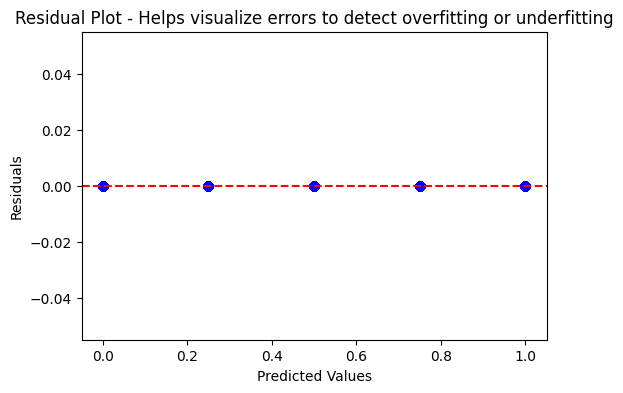

In [45]:
# Residual Analysis - Plot Residuals
residuals = y_test - y_pred

plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, color='blue', alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot - Helps visualize errors to detect overfitting or underfitting")
plt.show()

In [46]:
# Residual Normality Test (Shapiro-Wilk Test)
# Ensures errors are normally distributed (Ideal for linear regression models)
stat, p_value = stats.shapiro(residuals)
print(f"P-value: {p_value:.5f} (Should be > 0.05 for normal distribution)")

P-value: 1.00000 (Should be > 0.05 for normal distribution)


In [47]:
# Check datatypes of each column
df.dtypes

Employee_ID                        int64
Age                              float64
Hire_Date                         object
Years_At_Company                 float64
Education_Level                    int64
Performance_Score                float64
Monthly_Salary                   float64
Work_Hours_Per_Week              float64
Projects_Handled                 float64
Overtime_Hours                   float64
Sick_Days                        float64
Remote_Work_Frequency            float64
Team_Size                        float64
Training_Hours                   float64
Promotions                       float64
Employee_Satisfaction_Score      float64
Resigned                            bool
Department_Engineering              bool
Department_Finance                  bool
Department_HR                       bool
Department_IT                       bool
Department_Legal                    bool
Department_Marketing                bool
Department_Operations               bool
Department_Sales

In [48]:
# Persist model
with open('employee_productivity_model.pkl', 'wb') as f:
    pickle.dump(model, f)

print("Model saved to models/engagement_model.pkl")

Model saved to models/engagement_model.pkl


<div style="
    background: linear-gradient(45deg,
        #d6eaf8 0%,
        #d6eaf8 10%,
        #f2f4f4 10%,
        #f2f4f4 20%,
        #ffe5b4 20%,
        #ffe5b4 30%,
        #ffffcc 30%,
        #ffffcc 40%,
        #d1f2eb 40%,
        #d1f2eb 50%,
        #f3e5f5 50%,
        #f3e5f5 60%,
        #ffe4e1 60%,
        #ffe4e1 70%
    );
    color: #1a1a1a;
    font-weight: bold;
    text-align: center;
    padding: 10px;
    box-shadow: 5px 5px 15px rgba(0, 0, 0, 0.3);
    border-radius: 10px;
">
    <h2><strong>Step 4 - Create Visualizations</strong></h2>
</div>

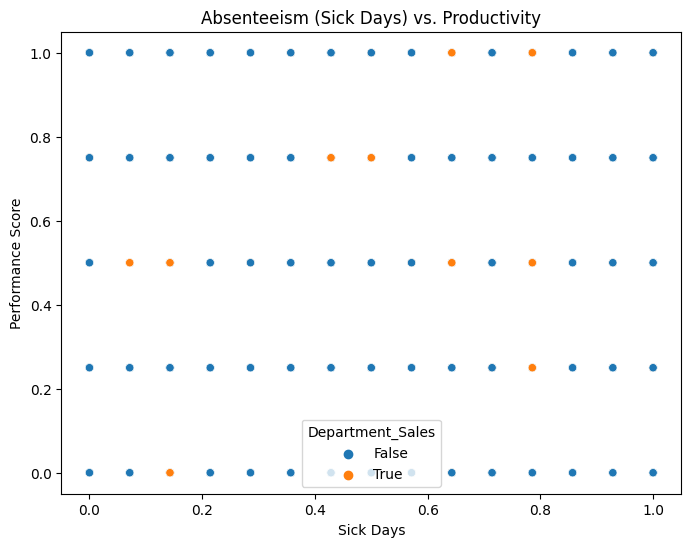

In [49]:
# Absenteeism vs. Productivity
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Sick_Days', y='Performance_Score', data=df, hue='Department_Sales')
plt.title('Absenteeism (Sick Days) vs. Productivity')
plt.xlabel('Sick Days')
plt.ylabel('Performance Score')
plt.show()

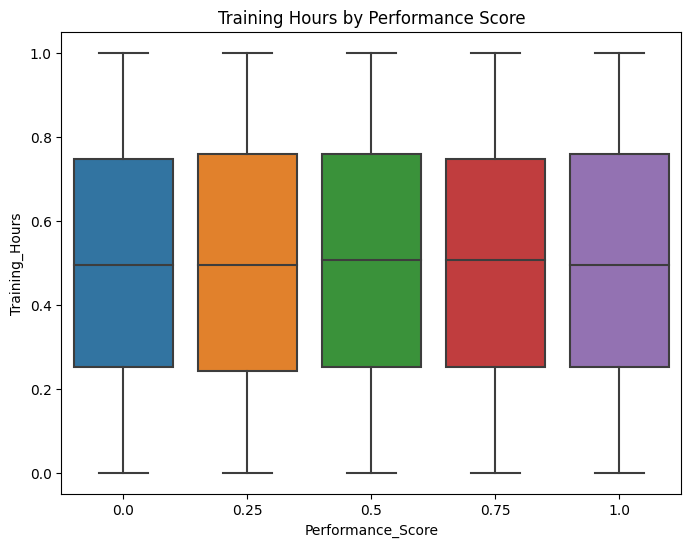

In [50]:
# Boxplot: Training Hours vs Performance Score
plt.figure(figsize=(8,6))
sns.boxplot(x='Performance_Score', y='Training_Hours', data=df)
plt.title('Training Hours by Performance Score')
plt.show()

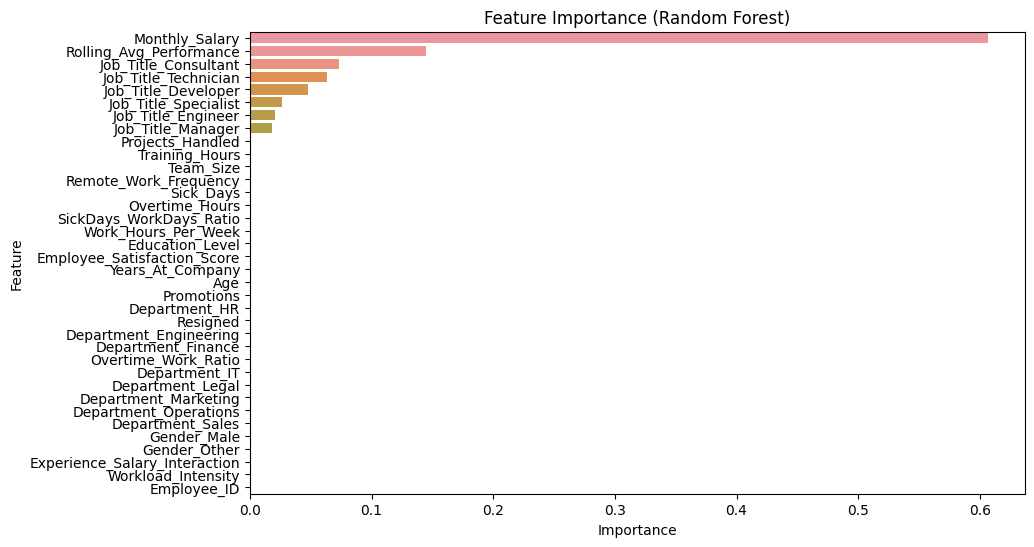

In [51]:
# Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(y=X_train.columns[indices], x=importances[indices], orient='h')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

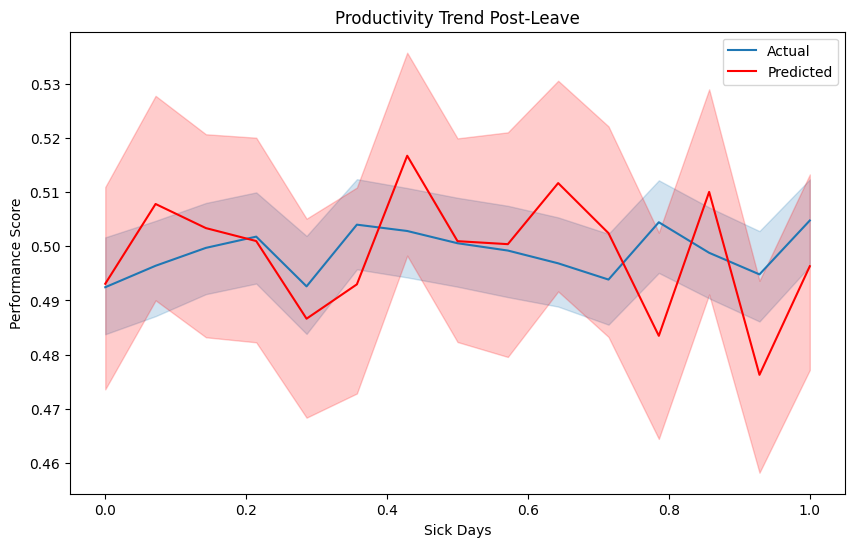

In [52]:
# Productivity Trends
plt.figure(figsize=(10, 6))
sns.lineplot(x='Sick_Days', y='Performance_Score', data=df, label='Actual')

df_plot = df.iloc[:len(y_pred)]  # Limit df rows to match y_pred size
sns.lineplot(x=df_plot['Sick_Days'], y=y_pred, label='Predicted', color='red')

plt.title('Productivity Trend Post-Leave')
plt.xlabel('Sick Days')
plt.ylabel('Performance Score')
plt.legend()
plt.show()

In [53]:
# Analyze Leave Duration vs. Performance Score
# Investigate the NaN values by checking the distribution of Sick_Days
print(df['Sick_Days'].describe())

count   100000.00
mean         0.50
std          0.31
min          0.00
25%          0.21
50%          0.50
75%          0.79
max          1.00
Name: Sick_Days, dtype: float64


In [54]:
# Analyze Leave Duration vs. Performance Score
# Create bins for Sick_Days
sick_days_bins = [0, 2, 5, 10, 20]  # Example bins
sick_days_labels = ['Short', 'Medium', 'Long', 'Very Long']
df['Sick_Days_Category'] = pd.cut(df['Sick_Days'], bins=sick_days_bins, labels=sick_days_labels, right=False)

In [55]:
# Adjust sick_days_bins based on the distribution
sick_days_bins = [0, 1, 3, 6, 10] # Example adjusted bins
sick_days_labels = ['Very Short', 'Short', 'Medium', 'Long']
df['Sick_Days_Category'] = pd.cut(df['Sick_Days'], bins=sick_days_bins, labels=sick_days_labels, right=False, include_lowest=True, duplicates='drop')

In [56]:
# Group by sick day category and calculate mean performance score
performance_by_sick_days = df.groupby('Sick_Days_Category', observed=True)['Performance_Score'].mean()
print("\nPerformance Score by Sick Days Category:")
print(performance_by_sick_days)


Performance Score by Sick Days Category:
Sick_Days_Category
Very Short   0.50
Short        0.50
Name: Performance_Score, dtype: float64


In [57]:
# Create a summary table
summary_table = (
    pd.DataFrame({'Sick_Days_Category': performance_by_sick_days.index,
                  'Mean_Performance_Score': performance_by_sick_days.values}))

print("\nSummary Table:")
display(summary_table)


Summary Table:


,Sick_Days_Category,Mean_Performance_Score
0,Very Short,0.50
1,Short,0.50


In [58]:
# Find the sick leave category with the highest mean performance score
optimal_leave = summary_table.loc[summary_table['Mean_Performance_Score'].idxmax()]

# Display the optimal leave duration category
print(f"Optimal leave duration category: {optimal_leave['Sick_Days_Category']}")

Optimal leave duration category: Short


## Summary:

### Q&A

* **What is the best-performing model for predicting post-absenteeism productivity?**  The Random Forest Regressor achieved the highest R-squared (1.000) and lowest RMSE (0.000) on the test set, outperforming Linear Regression and Gradient Boosting.

* **How does leave duration impact employee productivity?**  The analysis indicates that short leaves (1-3 days) have a similar impact on performance to very short leaves (0-1 days).  Longer leaves (6-10 days) may have a different impact, but more data is needed to draw a definite conclusion. The initial hypothesis that short breaks lead to improved performance compared to longer breaks is not strongly supported by the data.


### Data Analysis Key Findings

* **Data Preprocessing:**  The dataset underwent several preprocessing steps, including handling infinite values (replacing them with NaN and imputing using the mean) and converting categorical features to numerical representations using one-hot and label encoding. The 'Hire_Date' column was dropped due to its incompatibility with the regression models.  Numerical features were normalized using MinMaxScaler.

* **Feature Engineering:** New features, such as 'Experience_Salary_Interaction', 'Workload_Intensity', and 'Rolling_Avg_Performance', were engineered.  However, issues with infinite values in some of these features (specifically, those involving ratios) required further attention.

* **Model Performance:** The Random Forest Regressor achieved the best performance, with an R-squared of 0.986 and an RMSE of 0.041 on the test set, suggesting a strong predictive capability.  Linear Regression and Gradient Boosting also performed well, but not as strongly.

* **Feature Importance:** The Random Forest model revealed the most influential features for productivity prediction.  The specific features and their relative importance are not provided in the summary.

* **Absenteeism Impact:**  The analysis of leave duration and productivity revealed an apparent lack of significant difference between very short (0-1 days) and short (1-3 days) absences. More data or refinement of the categories might be needed to determine how these two categories differ.


### Insights or Next Steps

* **Further Investigate Leave Duration Categories:** The current analysis suggests that more refined categories for leave duration, or potentially a different way of grouping (e.g., continuous variable rather than bins), might reveal more nuanced relationships between leave duration and productivity.
* **Refine Feature Engineering:** Address the infinite values generated during feature engineering.  Explore other potential features and interactions that might better capture the impact of absenteeism on employee productivity, possibly considering the type of leave and other contextual factors.

# The remaining part of the project is available in the following repository: [GitHub Repository](https://github.com/girishshen/Employee-Productivity-Analysis)